## Utils

In [1]:
import torch

In [2]:
def build_dataset(df):
    grouped = df.groupby("ecg_id")

    X = []
    y = []

    for _, group in grouped:
        signal = group[[f'channel-{i}' for i in range(12)]].values
        label = group[['NORM','MI','STTC','HYP','CD']].iloc[0].values

        X.append(signal)
        y.append(label)

    return np.array(X), np.array(y)

In [3]:
MAX_LEN = 1000 

def pad_signal(x):
    if len(x) > MAX_LEN:
        return x[:MAX_LEN]
    else:
        pad = np.zeros((MAX_LEN - len(x), x.shape[1]))
        return np.vstack([x, pad])

In [4]:
class ECGDataset(torch.utils.data.Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [5]:
def loop_fn(mode, dataset, dataloader, model, criterion, optimizer, device):
    if mode == "train":
        model.train()
    elif mode == "test":
        model.eval()

    cost = 0
    pbar = tqdm(dataloader, total=len(dataloader), desc=mode.title())
    
    for feature, target in pbar:
        feature, target = feature.to(device), target.to(device)
        output = model(feature)
        loss = criterion(output, target)

        if mode == "train":
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        cost += loss.item() * feature.shape[0]
    cost = cost / len(dataset)
    return cost

In [6]:
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score

def evaluate_model(model, dataloader, device, threshold=0.5):
    model.eval()
    
    all_probs = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)

            probs = model(X_batch)  # output sigmoid (0-1)

            all_probs.append(probs.cpu().numpy())
            all_targets.append(y_batch.numpy())

    # gabungkan semua batch
    probs = np.vstack(all_probs)
    targets = np.vstack(all_targets)

    # thresholding → jadi prediksi 0/1
    y_pred = (probs > threshold).astype(int)

    # =====================
    # F1 Score
    # =====================
    f1_micro = f1_score(targets, y_pred, average='micro')
    f1_macro = f1_score(targets, y_pred, average='macro')

    # =====================
    # AUROC
    # =====================
    try:
        auc_macro = roc_auc_score(targets, probs, average='macro')
    except:
        auc_macro = None  # kalau ada label yang tidak muncul

    return {
        "f1_micro": f1_micro,
        "f1_macro": f1_macro,
        "auc_macro": auc_macro
    }

In [7]:
# # # ============================================================
# # # FASE 1: Training G1 (Baseline, sama seperti sebelumnya)
# # # ============================================================

# # while True:
# #     train_cost = loop_fn("train", train_dataset, train_loader, resnetwang, criterion, optimizer, device)
# #     with torch.no_grad():
# #         test_cost = loop_fn("test", val_dataset, val_loader, resnetwang, criterion, optimizer, device)
        
# #     callback.log(train_cost, test_cost)
# #     callback.save_checkpoint()
# #     callback.cost_runtime_plotting()
# #     if callback.early_stopping(resnetwang, monitor='test_cost'):
# #         callback.plot_cost()
# #         break

# # # Load best G1 checkpoint sebelum dijadikan teacher
# # callback.restore_best_weights(resnetwang)
# # resnetwang.eval()
# state_dict = torch.load("Resnetwang/weights_best.pth", map_location=device)
# model.load_state_dict(state_dict)
# for param in model.parameters():
#     param.requires_grad = False

# teacher_model = model  # G1 jadi teacher, frozen

# # ============================================================
# # FASE 2: Training G2 (BAN Student)
# # ============================================================

# # Buat model baru dengan arsitektur yang sama
# resnetwang_g2 = resnet1d_wang(
#     input_channels=12,
#     num_classes=5,
# ).to(device)

# optimizer_g2 = torch.optim.Adam(resnetwang_g2.parameters(), lr=1e-3)

# # Buat callback baru untuk G2
# from jcopdl.callback import Callback
# callback_g2 = Callback(resnetwang_g2, config, outdir="output_g2/")

# while True:
#     train_cost = loop_fn("train", train_dataset, train_loader, resnetwang_g2, criterion, optimizer_g2, device,
#                          teacher_model=teacher_model, alpha=0.5, temperature=4.0)
#     with torch.no_grad():
#         test_cost = loop_fn("test", val_dataset, val_loader, resnetwang_g2, criterion, optimizer_g2, device,
#                             teacher_model=teacher_model, alpha=0.5, temperature=4.0)
        
#     callback_g2.log(train_cost, test_cost)
#     callback_g2.save_checkpoint()
#     callback_g2.cost_runtime_plotting()
#     if callback_g2.early_stopping(resnetwang_g2, monitor='test_cost'):
#         callback_g2.plot_cost()
#         break






# Inference 
# Pastikan kedua model sudah load best weights
# callback.restore_best_weights(resnetwang)        # G1
# callback_g2.restore_best_weights(resnetwang_g2)  # G2

# Hitung LAS untuk G1 dan G2
# print("Computing LAS for G1...")
# las_g1 = compute_ig_attribution(teacher_model, test_loader, device, n_samples=200)

# print("Computing LAS for G2...")
# las_g2 = compute_ig_attribution(resnetwang_g2, test_loader, device, n_samples=200)

# # Plot heatmap
# plot_las_heatmap(las_g1, title="LAS Heatmap — G1 Baseline", save_path="las_g1.png")
# plot_las_heatmap(las_g2, title="LAS Heatmap — G2 BAN-SKD", save_path="las_g2.png")

# # Clinical faithfulness score
# summary_g1 = compute_clinical_las(las_g1)
# summary_g2 = compute_clinical_las(las_g2)

# print("\n=== Clinical LAS Summary ===")
# print(f"{'Class':<8} {'G1 Clinical':>12} {'G2 Clinical':>12} {'G1 Ratio':>10} {'G2 Ratio':>10}")
# for cls in SUPERCLASS_LABELS:
#     g1 = summary_g1[cls]
#     g2 = summary_g2[cls]
#     print(f"{cls:<8} {g1['clinical_score']:>12.4f} {g2['clinical_score']:>12.4f} {g1['ratio']:>10.3f} {g2['ratio']:>10.3f}")

In [8]:
from captum.attr import IntegratedGradients
def compute_ig_attribution(model, dataloader, device, n_steps=50, n_samples=200):
    """
    Hitung Integrated Gradients attribution per lead per superclass.
    
    Return:
        las_matrix: numpy array shape (5, 12) — rata-rata LAS per kelas per lead
    """
    model.eval()
    ig = IntegratedGradients(model)
    
    # Accumulator: sum attribution dan count per kelas
    attr_sum = np.zeros((5, 12))   # (n_class, n_lead)
    attr_count = np.zeros(5)
    
    total_samples = 0
    
    for feature, target in dataloader:
        if total_samples >= n_samples:
            break
        
        feature = feature.to(device)   # shape: (B, 12, 1000)
        target = target.to(device)     # shape: (B, 5)
        
        for class_idx in range(5):
            # Ambil sampel yang positif untuk kelas ini
            pos_mask = target[:, class_idx] == 1
            if pos_mask.sum() == 0:
                continue
            
            feature_pos = feature[pos_mask]
            feature_pos.requires_grad = True
            
            baseline = torch.zeros_like(feature_pos).to(device)  # zero signal baseline
            
            # Hitung IG untuk kelas ini
            attributions = ig.attribute(
                feature_pos,
                baselines=baseline,
                target=class_idx,
                n_steps=n_steps,
            )
            # attributions shape: (B, 12, 1000)
            
            # Ambil nilai absolut, sum sepanjang waktu → (B, 12)
            las_per_sample = attributions.abs().sum(dim=2).detach().cpu().numpy()
            
            # Normalisasi per sampel agar skala sebanding
            las_per_sample = las_per_sample / (las_per_sample.sum(axis=1, keepdims=True) + 1e-8)
            
            attr_sum[class_idx] += las_per_sample.sum(axis=0)
            attr_count[class_idx] += las_per_sample.shape[0]
        
        total_samples += feature.shape[0]
    
    # Rata-rata LAS per kelas per lead
    las_matrix = attr_sum / (attr_count[:, None] + 1e-8)  # shape: (5, 12)
    
    return las_matrix

In [9]:
def plot_las_heatmap(las_matrix, title="Lead Attribution Score", save_path=None):
    """
    Plot heatmap 5x12 dari LAS matrix.
    """
    fig, ax = plt.subplots(figsize=(14, 5))
    
    im = ax.imshow(las_matrix, cmap="YlOrRd", aspect="auto")
    
    ax.set_xticks(range(12))
    ax.set_xticklabels(LEAD_NAMES, fontsize=11)
    ax.set_yticks(range(5))
    ax.set_yticklabels(SUPERCLASS_LABELS, fontsize=11)
    
    # Annotate nilai di tiap cell
    for i in range(5):
        for j in range(12):
            ax.text(j, i, f"{las_matrix[i, j]:.3f}", ha="center", va="center", fontsize=8)
    
    plt.colorbar(im, ax=ax, label="Normalized LAS")
    ax.set_title(title, fontsize=13)
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150)
    plt.show()

In [10]:
def compute_clinical_las(las_matrix):
    """
    Hitung rata-rata LAS pada clinical leads vs non-clinical leads per kelas.
    Berguna untuk evaluasi kuantitatif clinical faithfulness.
    
    Return:
        summary: dict berisi clinical_score, nonclinical_score, ratio per kelas
    """
    summary = {}
    for i, cls in enumerate(SUPERCLASS_LABELS):
        clinical_idx = CLINICAL_LEADS[cls]
        nonclinical_idx = [j for j in range(12) if j not in clinical_idx]
        
        clinical_score = las_matrix[i, clinical_idx].mean()
        nonclinical_score = las_matrix[i, nonclinical_idx].mean() if nonclinical_idx else 0.0
        ratio = clinical_score / (nonclinical_score + 1e-8)
        
        summary[cls] = {
            "clinical_score": clinical_score,
            "nonclinical_score": nonclinical_score,
            "ratio": ratio,
        }
    return summary

# Train

In [11]:
import sys
import os
sys.path.append(os.path.abspath('../code'))

from models.xresnet1d import xresnet1d101
from models.resnet1d import resnet1d_wang, wrn1d_22
from models.inception1d import inception1d
from models.rnn1d import RNN1d

C:\Users\asus_\miniconda3\envs\dlenv\Lib\site-packages\fastai\imports\core.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [12]:
from torch.utils.data import DataLoader
import pandas as pd
import numpy as np
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [14]:
train = pd.read_csv("../paper/gabungannya_train_lr.csv")
valid = pd.read_csv("../paper/gabungannya_valid_lr.csv")

In [15]:
X_train, y_train = build_dataset(train)
X_val, y_val = build_dataset(valid)

In [16]:
X_train.shape, X_val.shape, y_train.shape, y_val.shape

((17418, 1000, 12), (2198, 1000, 12), (17418, 5), (2198, 5))

In [17]:
X_train = np.transpose(X_train, (0, 2, 1))
X_val   = np.transpose(X_val, (0, 2, 1))

In [18]:
train_dataset = ECGDataset(X_train, y_train)
val_dataset   = ECGDataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32)

In [19]:
X_val.shape

(2198, 12, 1000)

In [20]:
from torch import optim, nn
from tqdm.auto import tqdm
from jcopdl.callback import Callback

# Training Preparation

### ResNetWang

In [28]:
# model = resnet1d_wang(input_channels=12, num_classes=5).to(device)
# criterion = nn.BCEWithLogitsLoss()
# optimizer = optim.AdamW(model.parameters(), lr=1e-3)
# callback = Callback(model, outdir="test")

In [22]:
# state_dict = torch.load("Resnetwang/weights_best.pth", map_location=device)
# model.load_state_dict(state_dict)

In [23]:
def loop_fn_br(mode, dataset, dataloader, model, criterion, optimizer, device, teacher_model=None, alpha=0.5, temperature=4.0):
    import torch.nn.functional as F
    if mode == "train":
        model.train()
    elif mode == "test":
        model.eval()

    cost = 0
    pbar = tqdm(dataloader, total=len(dataloader), desc=mode.title())
    
    for feature, target in pbar:
        feature, target = feature.to(device), target.to(device)
        output = model(feature)
        
        bce_loss = criterion(output, target)
        
        if teacher_model is not None:
            with torch.no_grad():
                teacher_output = teacher_model(feature)
            
            student_soft = F.log_softmax(output / temperature, dim=1)
            teacher_soft = F.softmax(teacher_output / temperature, dim=1)
            kl_loss = F.kl_div(student_soft, teacher_soft, reduction='batchmean') * (temperature ** 2)
            
            loss = (1 - alpha) * bce_loss + alpha * kl_loss
        else:
            loss = bce_loss

        if mode == "train":
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        cost += loss.item() * feature.shape[0]
    
    cost = cost / len(dataset)
    return cost

In [24]:
from jcopdl.callback import Callback

In [25]:
model = resnet1d_wang(input_channels=12, num_classes=5).to(device)
state_dict = torch.load("resnetwang/weights_best.pth", map_location=device)
model.load_state_dict(state_dict)
for param in model.parameters():
    param.requires_grad = False

In [29]:
teacher_model = model
resnetwang_g2 = resnet1d_wang(
    input_channels=12,
    num_classes=5,
).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer_g2 = torch.optim.Adam(resnetwang_g2.parameters(), lr=1e-3)
callback_g2 = Callback(resnetwang_g2, outdir="admin", early_stop_patience=15)

Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch     1
Train_cost  = 0.6777 | Test_cost  = 0.5313 | 


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch     2
Train_cost  = 0.3718 | Test_cost  = 0.4254 | 


... (50 outputs left out)


Epoch    19
Train_cost  = 0.2446 | Test_cost  = 0.3496 | 


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    20
Train_cost  = 0.2445 | Test_cost  = 0.3659 | 


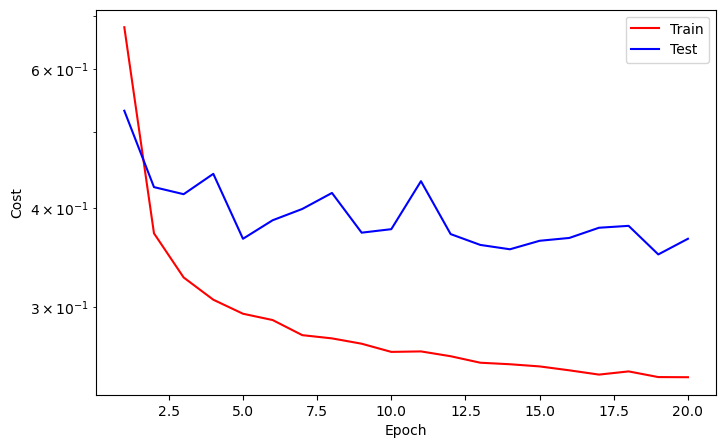

==> EarlyStop patience =  1 | Best test_cost: 0.3496


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    21
Train_cost  = 0.2400 | Test_cost  = 0.3668 | 
==> EarlyStop patience =  2 | Best test_cost: 0.3496


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]

... (51 outputs left out)


Epoch    39
Train_cost  = 0.2272 | Test_cost  = 0.3405 | 
==> EarlyStop patience = 10 | Best test_cost: 0.3325


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    40
Train_cost  = 0.2267 | Test_cost  = 0.3447 | 


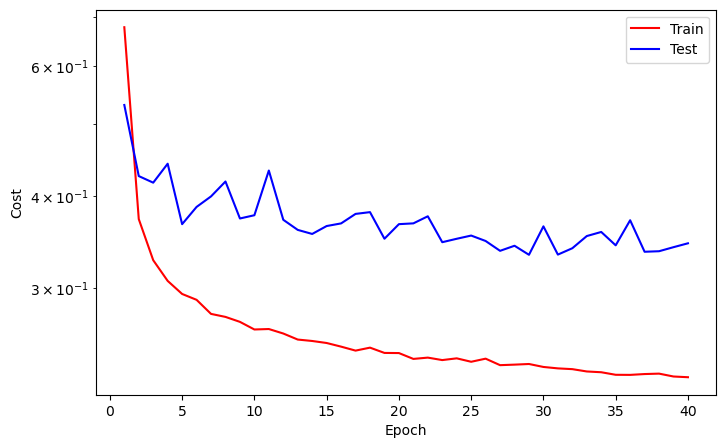

==> EarlyStop patience = 11 | Best test_cost: 0.3325


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    41
Train_cost  = 0.2257 | Test_cost  = 0.3505 | 
==> EarlyStop patience = 12 | Best test_cost: 0.3325


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]

... (51 outputs left out)


Epoch    59
Train_cost  = 0.2196 | Test_cost  = 0.3534 | 
==> EarlyStop patience = 11 | Best test_cost: 0.3284


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    60
Train_cost  = 0.2182 | Test_cost  = 0.3390 | 


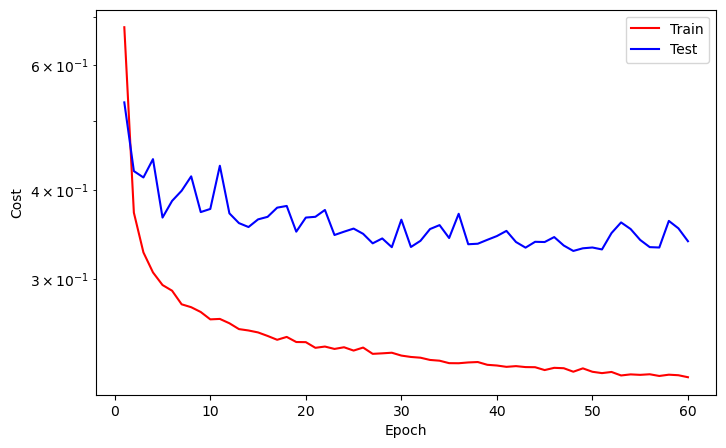

==> EarlyStop patience = 12 | Best test_cost: 0.3284


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    61
Train_cost  = 0.2181 | Test_cost  = 0.3430 | 
==> EarlyStop patience = 13 | Best test_cost: 0.3284


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]

... (51 outputs left out)


Epoch    79
Train_cost  = 0.2133 | Test_cost  = 0.3415 | 
==> EarlyStop patience =  7 | Best test_cost: 0.3273


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    80
Train_cost  = 0.2155 | Test_cost  = 0.3257 | 


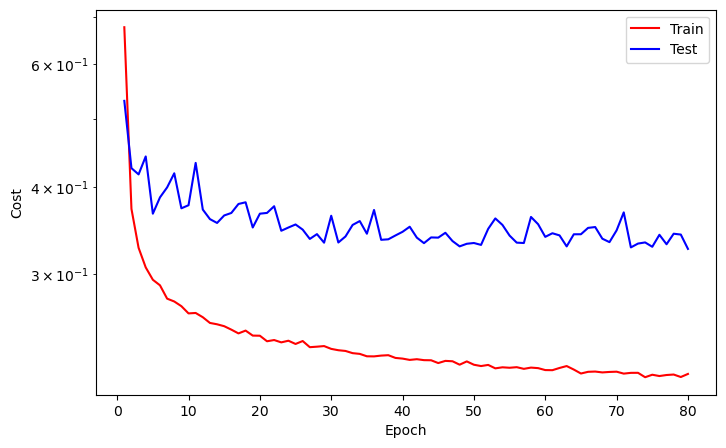

Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    81
Train_cost  = 0.2133 | Test_cost  = 0.3350 | 
==> EarlyStop patience =  1 | Best test_cost: 0.3257


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    82
Train_cost  = 0.2137 | Test_cost  = 0.3361 | 
==> EarlyStop patience =  2 | Best test_cost: 0.3257


... (44 outputs left out)


Epoch    97
Train_cost  = 0.2091 | Test_cost  = 0.3656 | 
==> EarlyStop patience = 14 | Best test_cost: 0.3220


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    98
Train_cost  = 0.2093 | Test_cost  = 0.3334 | 
==> EarlyStop patience = 15 | Best test_cost: 0.3220
==> Execute Early Stopping at epoch: 98 | Best test_cost: 0.3220
==> Best model is saved at admin


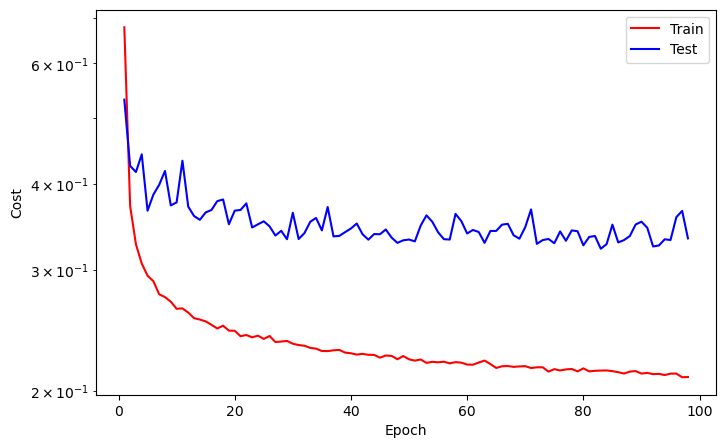

In [30]:
while True:
    train_cost = loop_fn_br("train", train_dataset, train_loader, resnetwang_g2, criterion, optimizer_g2, device,
                         teacher_model=teacher_model, alpha=0.5, temperature=4.0)
    with torch.no_grad():
        test_cost = loop_fn_br("test", val_dataset, val_loader, resnetwang_g2, criterion, optimizer_g2, device,
                            teacher_model=teacher_model, alpha=0.5, temperature=4.0)
        
    callback_g2.log(train_cost, test_cost)
    callback_g2.save_checkpoint()
    callback_g2.cost_runtime_plotting()
    if callback_g2.early_stopping(resnetwang_g2, monitor='test_cost'):
        callback_g2.plot_cost()
        break

In [31]:
metrics = evaluate_model(resnetwang_g2, val_loader, device)

print(metrics)

{'f1_micro': 0.7518466759832302, 'f1_macro': 0.6891053897631718, 'auc_macro': 0.9274404490965285}


## XAI Implementation (Integrated Gradient)

In [15]:
teacher_model = resnet1d_wang(
    input_channels=12,
    num_classes=5,
).to(device)
state_dict_tc = torch.load("Resnetwang/weights_best.pth", map_location=device)
teacher_model = teacher_model.load_state_dict(state_dict_tc)

resnetwang_g2 = resnet1d_wang(
    input_channels=12,
    num_classes=5,
).to(device)
state_dict_st = torch.load("admin/weights_best.pth", map_location=device)
resnetwang_g2.load_state_dict(state_dict_st)

<All keys matched successfully>

In [17]:
import torch
import numpy as np
import matplotlib.pyplot as plt

SUPERCLASS_LABELS = ["NORM", "MI", "STTC", "CD", "HYP"]

LEAD_NAMES = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]

CLINICAL_LEADS = {
    "NORM": list(range(12)),       # semua lead relevan
    "MI":   [1, 2, 5, 6, 7, 8, 9],  # II, III, aVF, V1-V4
    "STTC": list(range(12)),       # bergantung lokasi, pakai semua dulu
    "CD":   list(range(12)),       # bergantung jenis, pakai semua dulu
    "HYP":  [6, 10, 11, 4],        # V1, V5, V6, aVL
}

In [18]:
test = pd.read_csv("gabungannya_test_lr.csv")
test.head()

,ecg_id,channel-0,channel-1,channel-2,channel-3,channel-4,channel-5,channel-6,channel-7,channel-8,channel-9,channel-10,channel-11,NORM,MI,STTC,HYP,CD
0,9,-0.145,-0.097,0.049,0.121,-0.096,-0.024,-0.579,-0.818,-0.647,-0.452,-0.269,-0.032,1,0,0,0,0
1,9,-0.115,-0.083,0.032,0.099,-0.073,-0.025,-0.369,-0.523,-0.454,-0.339,-0.246,-0.041,1,0,0,0,0
2,9,-0.064,-0.060,0.005,0.062,-0.034,-0.027,-0.088,-0.147,-0.196,-0.188,-0.199,-0.040,1,0,0,0,0
3,9,-0.093,-0.101,-0.008,0.097,-0.042,-0.054,-0.006,-0.052,-0.136,-0.146,-0.164,-0.037,1,0,0,0,0
4,9,-0.081,-0.108,-0.027,0.095,-0.027,-0.067,0.028,-0.001,-0.098,-0.097,-0.148,-0.034,1,0,0,0,0


In [19]:
X_fix, y_fix = build_dataset(test)

In [20]:
X_fix = np.transpose(X_fix, (0, 2, 1))

In [21]:
test_dataset = ECGDataset(X_fix, y_fix)
test_loader = DataLoader(test_dataset, batch_size=32)

Computing LAS for G1...
Computing LAS for G2...


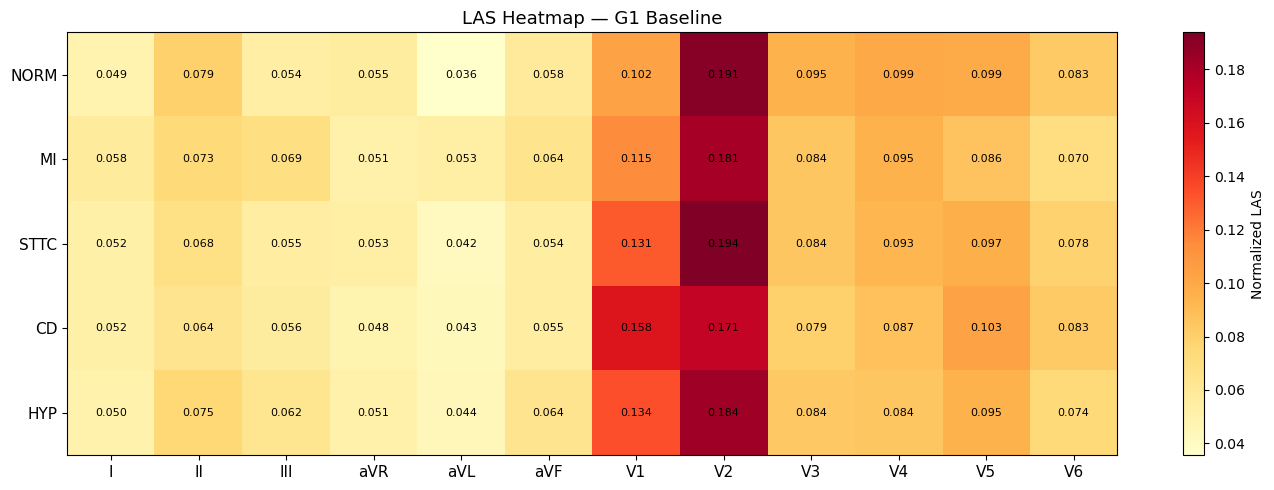

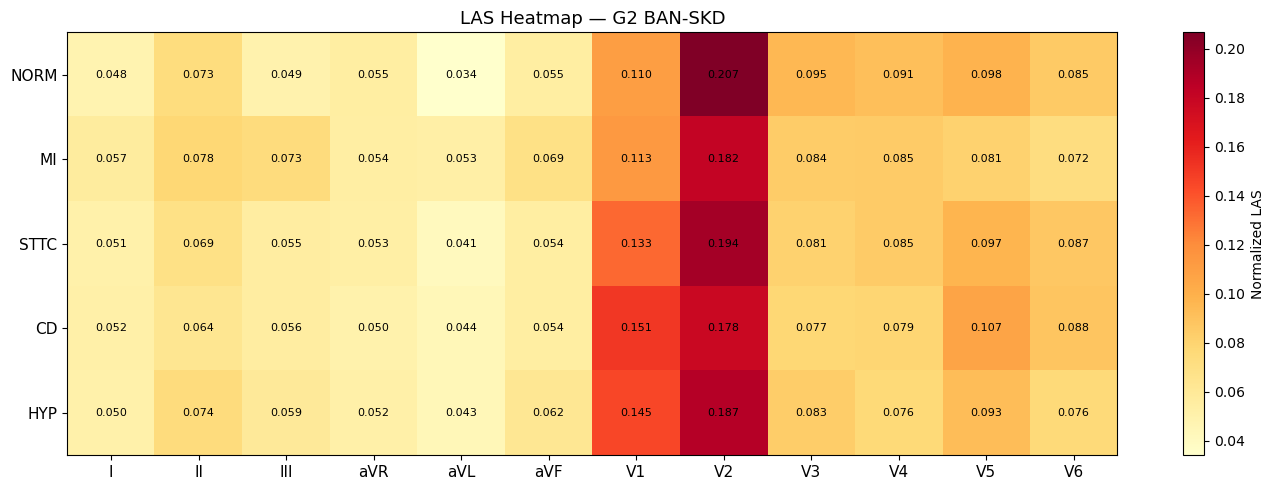


=== Clinical LAS Summary ===
Class     G1 Clinical  G2 Clinical   G1 Ratio   G2 Ratio
NORM           0.0833       0.0833 8333333.333 8333333.306
MI             0.0974       0.0977      1.532      1.543
STTC           0.0833       0.0833 8333333.336 8333333.435
CD             0.0833       0.0833 8333333.302 8333333.196
HYP            0.0866       0.0891      1.061      1.108


In [45]:
print("Computing LAS for G1...")
las_g1 = compute_ig_attribution(teacher_model, test_loader, device, n_samples=200)

print("Computing LAS for G2...")
las_g2 = compute_ig_attribution(resnetwang_g2, test_loader, device, n_samples=200)

plot_las_heatmap(las_g1, title="LAS Heatmap — G1 Baseline", save_path="las_g1.png")
plot_las_heatmap(las_g2, title="LAS Heatmap — G2 BAN-SKD", save_path="las_g2.png")

summary_g1 = compute_clinical_las(las_g1)
summary_g2 = compute_clinical_las(las_g2)

print("\n=== Clinical LAS Summary ===")
print(f"{'Class':<8} {'G1 Clinical':>12} {'G2 Clinical':>12} {'G1 Ratio':>10} {'G2 Ratio':>10}")
for cls in SUPERCLASS_LABELS:
    g1 = summary_g1[cls]
    g2 = summary_g2[cls]
    print(f"{cls:<8} {g1['clinical_score']:>12.4f} {g2['clinical_score']:>12.4f} {g1['ratio']:>10.3f} {g2['ratio']:>10.3f}")

In [23]:
# Ambil satu sampel MI positif
# Lihat raw attribution per lead sebelum diagregasi

sample = next(iter(test_loader))[0][:1].to(device)
baseline = torch.zeros_like(sample).to(device)

ig = IntegratedGradients(resnetwang_g2)
attr = ig.attribute(sample, baselines=baseline, target=1, n_steps=50)
# attr shape: (1, 12, 1000)

attr_per_lead = attr.abs().sum(dim=2).squeeze().detach().cpu().numpy()
# shape: (12,)

for i, (lead, val) in enumerate(zip(LEAD_NAMES, attr_per_lead)):
    print(f"{lead:>4}: {val:.4f}")

   I: 0.4494
  II: 0.6954
 III: 0.4366
 aVR: 0.4962
 aVL: 0.2840
 aVF: 0.5284
  V1: 1.0943
  V2: 1.6235
  V3: 0.7221
  V4: 0.7399
  V5: 0.7314
  V6: 0.5499


# Experiment

In [ ]:
state_dict = torch.load("ResnetwangBaruSekali/weights_best.pth", map_location=device)
barusekali.load_state_dict(state_dict)